In [2]:
%load_ext autoreload
%autoreload 2
import numpy as np
import D4CMPP_TLC
import SSC
from rdkit import Chem
import matplotlib.pyplot as plt

In [ ]:
p=SSC.train(data='C_paper', 
            molecule_columns=['Smiles','eluent1_smiles','eluent2_smiles',], 
            numeric_input_columns=['ratio1','ratio2'], 
            target=['Rf'],
            network='CLI_segment_attention_big_MLP',
            device = 'cuda:2',)
            # max_epoch = 10000,
            # early_stopping_patience = 5000)

/home/ufslab223/KSW/SSC_org_git/D4CMPP_TLC
Training from scratch to ./_Models/BLI_segment_attention_big_MLP_concat_C_paper_Rf_620_20260620_051200
Sculptor Index: (6, 2, 0)
Device: cuda:2
#params: 234113
Train: 11797, Val: 1440, Test: 1474


Epoch 33:   2%|▏         | 33/2000 [15:02<14:46:17, 27.03s/it, train_loss=0.399, val_loss=0.327]

In [4]:
CLI_segment= SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3("CLI_segment_attention_big_MLP_C_paper_Rf_620_20260619_041103")

founded model: ./_Models/CLI_segment_attention_big_MLP_C_paper_Rf_620_20260619_041103
Device: cuda:3
#params: 207170
Loading params from ./_Models/CLI_segment_attention_big_MLP_C_paper_Rf_620_20260619_041103/final.pth


/home/ufslab223/anaconda3/envs/ksw_pyg_dgl/lib/python3.10/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


Sculptor Index: (6, 2, 0)


In [15]:
score["attn_size"][0]

array([3])

In [16]:
import pandas as pd

smi = "Brc1cccc(N2CCCCC2)c1"
elu1 = "CCCCCC"
elu2 = "O=C(OCC)C"
r1 = 0.8
r2 = 0.2

score = CLI_segment.get_score(smi, elu1, elu2, r1, r2)
print(score.keys())
frag = CLI_segment.get_fragment(smi)

df = pd.DataFrame({
    "frag_idx": list(range(len(frag))),
    "frag_smiles": [f.smiles for f in frag],
    "atoms": [f.atoms for f in frag],
    "attn1": score["attn1"].reshape(-1),
    "attn2": score["attn2"].reshape(-1),
    "attn1_ratio": score["attn1_ratio"].reshape(-1),
    "attn2_ratio": score["attn2_ratio"].reshape(-1),
})

df["attn_total_ratio"] = df["attn1_ratio"] + df["attn2_ratio"]
df

Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
dict_keys(['a0', 'a1', 'y', 'attn1', 'attn2', 'attn1_ratio', 'attn2_ratio', 'attn_size'])


,frag_idx,frag_smiles,atoms,attn1,attn2,attn1_ratio,attn2_ratio,attn_total_ratio
0,0,*Br,[0],0.561063,-0.056004,0.448851,-0.011201,0.437650
1,1,C1CCNCC1,"[6, 7, 8, 9, 10, 11]",1.694104,2.075374,1.355283,0.415075,1.770358
2,2,c1ccccc1,"[1, 2, 3, 4, 5, 12]",0.099357,-0.743150,0.079485,-0.148630,-0.069145


In [39]:
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, display, Markdown
import numpy as np


def group_scores_to_atom_scores(mol, frag, group_scores, mode="mean"):
    atom_values = {i: [] for i in range(mol.GetNumAtoms())}

    for f, s in zip(frag, group_scores):
        for a in f.atoms:
            atom_values[int(a)].append(float(s))

    atom_scores = {}
    for atom_idx, vals in atom_values.items():
        if not vals:
            continue
        if mode == "sum":
            atom_scores[atom_idx] = float(np.sum(vals))
        else:
            atom_scores[atom_idx] = float(np.mean(vals))
    return atom_scores


def score_to_color(x, vmax):
    if vmax == 0:
        return (1.0, 1.0, 1.0)

    t = min(abs(x) / vmax, 1.0)
    if x >= 0:
        return (1.0, 1.0 - t, 1.0 - t)  # white -> red
    return (1.0 - t, 1.0 - t, 1.0)      # white -> blue


def fragment_score_text(frag, group_scores, key):
    lines = [f"**{key} fragment scores**"]
    for idx, (f, score_value) in enumerate(zip(frag, group_scores)):
        atoms = [int(a) for a in f.atoms]
        lines.append(f"- frag {idx}, atoms {atoms}: {float(score_value):.6g}")
    return "\n".join(lines)


def draw_attention_on_mol(smi, frag, group_scores, title="", key="score", vmax=None):
    mol = Chem.MolFromSmiles(smi)
    mol = Chem.Mol(mol)

    atom_scores = group_scores_to_atom_scores(mol, frag, group_scores)
    if vmax is None:
        vmax = max([abs(v) for v in atom_scores.values()] + [1e-12])

    highlight_atoms = list(atom_scores.keys())
    highlight_colors = {
        i: score_to_color(atom_scores[i], vmax)
        for i in highlight_atoms
    }
    highlight_radii = {
        i: 0.35 + 0.25 * min(abs(atom_scores[i]) / vmax, 1.0)
        for i in highlight_atoms
    }

    drawer = rdMolDraw2D.MolDraw2DSVG(300, 250)
    opts = drawer.drawOptions()
    opts.addAtomIndices = True

    drawer.DrawMolecule(
        mol,
        legend=title,
        highlightAtoms=highlight_atoms,
        highlightAtomColors=highlight_colors,
        highlightAtomRadii=highlight_radii,
    )
    drawer.FinishDrawing()
    display(SVG(drawer.GetDrawingText()))
    display(Markdown(fragment_score_text(frag, group_scores, key)))


def draw_solvent_attentions(smi, frag, score, elu1="eluent1", elu2="eluent2", ratio=False):
    """Draw CLI-style attn1/attn2, or attn1_ratio/attn2_ratio when ratio=True."""
    key1 = "attn1_ratio" if ratio else "attn1"
    key2 = "attn2_ratio" if ratio else "attn2"

    attn1 = score[key1].reshape(-1)
    attn2 = score[key2].reshape(-1)
    vmax = max(np.max(np.abs(attn1)), np.max(np.abs(attn2)), 1e-12)

    label = "ratio-weighted " if ratio else "raw "
    draw_attention_on_mol(smi, frag, attn1, title=f"{label}{key1}: {elu1}", key=key1, vmax=vmax)
    draw_attention_on_mol(smi, frag, attn2, title=f"{label}{key2}: {elu2}", key=key2, vmax=vmax)


def draw_bli_attention(smi, frag, score, elu1="eluent1", elu2="eluent2", ratio=None):
    """Draw BLI-style single attn score for the ratio-weighted bulk eluent representation."""
    key = "attn"
    attn = score[key].reshape(-1)
    vmax = max(np.max(np.abs(attn)), 1e-12)

    if ratio is None:
        title = f"{key}: bulk eluent ({elu1} / {elu2})"
    else:
        title = f"{key}: bulk eluent ({elu1} / {elu2}, ratio={ratio})"
    draw_attention_on_mol(smi, frag, attn, title=title, key=key, vmax=vmax)


def draw_attention_by_model_type(smi, frag, score, elu1="eluent1", elu2="eluent2", ratio=False, model_type="CLI"):
    """Dispatch attention visualization for CLI-style two-attn or BLI-style single-attn outputs."""
    if model_type.upper() == "BLI":
        return draw_bli_attention(smi, frag, score, elu1=elu1, elu2=elu2, ratio=ratio)
    return draw_solvent_attentions(smi, frag, score, elu1=elu1, elu2=elu2, ratio=ratio)


Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].


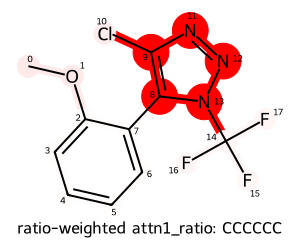

**attn1_ratio fragment scores**
- frag 0, atoms [1, 0]: 0.321619
- frag 1, atoms [10]: 0.25911
- frag 2, atoms [15, 16, 17, 14]: 0.121078
- frag 3, atoms [2, 3, 4, 5, 6, 7]: 0.0429906
- frag 4, atoms [8, 9, 11, 12, 13]: 3.8233

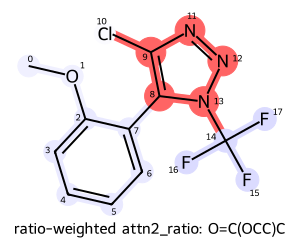

**attn2_ratio fragment scores**
- frag 0, atoms [1, 0]: -0.211567
- frag 1, atoms [10]: -0.0587248
- frag 2, atoms [15, 16, 17, 14]: -0.536076
- frag 3, atoms [2, 3, 4, 5, 6, 7]: -0.321026
- frag 4, atoms [8, 9, 11, 12, 13]: 2.30913

In [55]:

# ratio=False: visualize raw attn1/attn2.
# ratio=True: visualize ratio-weighted attn1_ratio/attn2_ratio.
smi = "COc1ccccc1-c1c(Cl)nnn1C(F)(F)F"
elu1 = "CCCCCC"
elu2 = "O=C(OCC)C"
r1 = 0.5
r2 = 0.5
score = CLI_segment.get_score(smi, elu1, elu2, r1, r2)
frag = CLI_segment.get_fragment(smi)
draw_solvent_attentions(smi, frag, score, elu1=elu1, elu2=elu2, ratio=True)

In [56]:
BLI_segment= SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3("BLI_segment_attention_big_MLP_C_paper_Rf_620_20260619_045523")

founded model: ./_Models/BLI_segment_attention_big_MLP_C_paper_Rf_620_20260619_045523
Device: cuda:2
#params: 207170
Loading params from ./_Models/BLI_segment_attention_big_MLP_C_paper_Rf_620_20260619_045523/final.pth
Sculptor Index: (6, 2, 0)


In [57]:
# BLI uses a single attention score over the ratio-weighted bulk eluent representation.
smi = "COc1ccccc1-c1c(Cl)nnn1C(F)(F)F"
elu1 = "CCCCCC"
elu2 = "O=C(OCC)C"
r1 = 0.5
r2 = 0.5
score = BLI_segment.get_score(smi, elu1, elu2, r1, r2)
frag = BLI_segment.get_fragment(smi)
draw_bli_attention(smi, frag, score, elu1=elu1, elu2=elu2, ratio=(r1, r2))

Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].


NameError: name 'attn1' is not defined

In [33]:
print(a.scaler.scaler.mean_, a.scaler.scaler.var_)

[0.44897715] [0.0452323]


In [38]:
"Cc1ccccc1/C(CN1C(=O)c2ccccc2C1=O)=C(\C=C\c1ccccc1)c1ccccc1"
"Brc1cccc(N2CCCCC2)c1"
"O=[N+]([O-])c1ccc(CBr)cc1"

array([[0.661656]])

In [72]:
l_eq, l_sw, l_full_eq = [], [], []
smi = "O=[N+]([O-])c1ccc(CBr)cc1"
for i in range(10):
    l_eq.append(
        a_eq.get_score(smi,
              "CCCCCC",
              "CCOC(C)=O",
              0.1*i,
              0.1*(10-i),)
    )
    l_sw.append(
        a_sw.get_score(smi,
              "CCCCCC",
              "CCOC(C)=O",
              0.1*i,
              0.1*(10-i),)
    )
    l_full_eq.append(
        a_full_eq2.get_score(smi,
              "CCCCCC",
              "CCOC(C)=O",
              0.1*i,
              0.1*(10-i),)
    )

Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
Positional arguments are provided. Note that arguments should be in the orde

In [73]:
y_sw = a_sw.scaler.scaler.inverse_transform(np.concatenate([_['y'] for _ in l_sw]))
y_eq = a_eq.scaler.scaler.inverse_transform(np.concatenate([_['y'] for _ in l_eq]))
y_full_eq = a_full_eq2.scaler.scaler.inverse_transform(np.concatenate([_['y'] for _ in l_full_eq]))

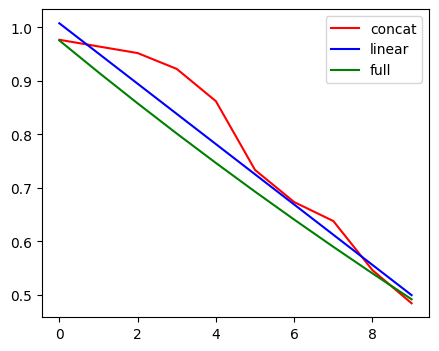

In [74]:
plt.figure(figsize=(5,4))
plt.plot(y_sw, 'r-', label = 'concat')
plt.plot(y_eq, 'b-', label = 'linear')
plt.plot(y_full_eq, 'g-', label= 'full')
plt.legend()

In [62]:
l_full_eq[0]

{'a0': array([[0.]], dtype=float32),
 'a1': array([[0.37605792]], dtype=float32),
 'b1': array([[0.45099527]], dtype=float32),
 'y': array([[0.45099527]], dtype=float32),
 'a3': array([[-4.206984]], dtype=float32),
 'b3': array([[-1.7956963]], dtype=float32),
 'd1': array([[16.15748]], dtype=float32)}